# Lab 6: Filtering in the Frequency Domain

ARTI403 Image Processing  
Maan Abdullah Alghamdi  
2240001433

I implement the procedural Laplacian example and the assessed Sobel X/Y filters using the same Cameraman image. I display the frequency spectra, signed spatial responses, and combined Sobel edge magnitude.

## 1. Setup and input image

I load the bundled 512 x 512 grayscale Cameraman image from scikit-image and resize it to 256 x 256 with Pillow Lanczos resampling. This replaces the manual's scikit-image resize step so that running my notebook needs only NumPy, Matplotlib, and Pillow. Pixel values are floating point in [0, 1]. I run all cells from top to bottom with this notebook's folder as the working directory; no image download is needed.

Image shape: (256, 256); dtype: float64
Intensity range: [0.0000, 1.0000]


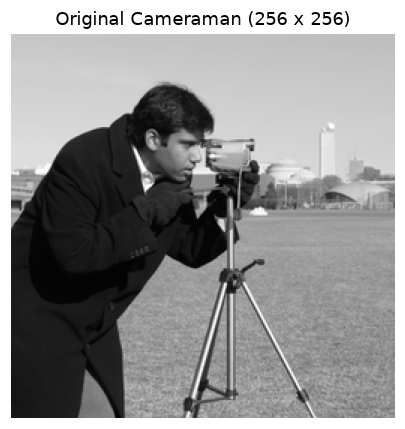

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from numpy.fft import fft2, ifft2, fftshift, ifftshift

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
image_path = Path('images') / 'cameraman.png'
with Image.open(image_path) as source:
    image = np.asarray(
        source.convert('L').resize((256, 256), Image.Resampling.LANCZOS),
        dtype=np.float64
    ) / 255.0
M, N = image.shape
F = fft2(image)
print(f'Image shape: {image.shape}; dtype: {image.dtype}')
print(f'Intensity range: [{image.min():.4f}, {image.max():.4f}]')
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(image, cmap='gray', vmin=0, vmax=1)
ax.set_title('Original Cameraman (256 x 256)')
ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Procedural task: Laplacian filtering

I use H(u,v) = -4 pi^2 (u^2 + v^2), where u and v are frequencies in cycles per pixel. The array from fftfreq is in unshifted FFT order, which matches fft2(image); it is not centered. I multiply F by H, then take the real part of the inverse FFT. I use fftshift only when displaying a spectrum. The Laplacian suppresses constant intensity and emphasizes rapid changes; its signed response is not a sharpened image.

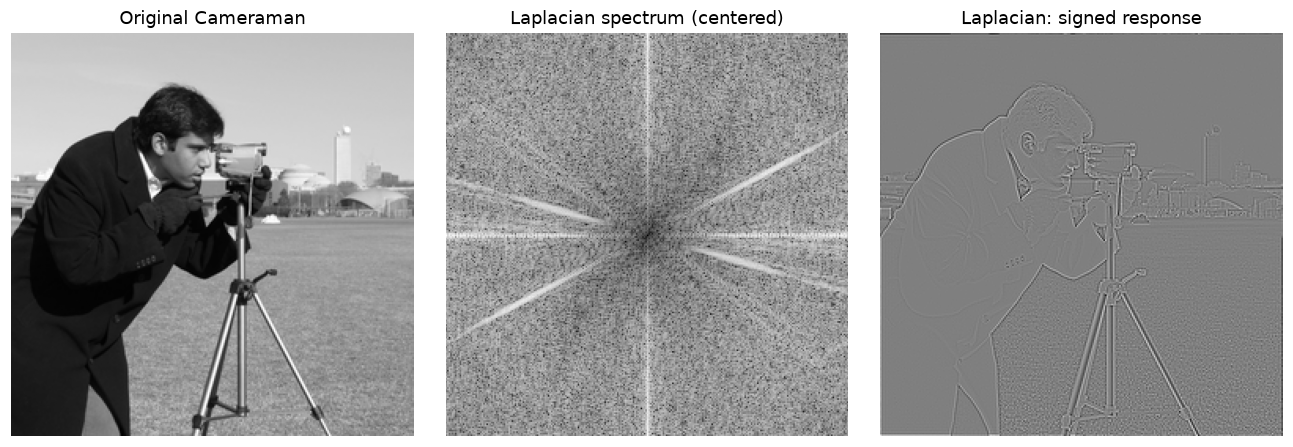

Laplacian range: -2.360822 to 1.953270


In [2]:
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)
laplacian_filter = -4 * np.pi**2 * (u**2 + v**2)
F_lap = F * laplacian_filter
laplacian_complex = ifft2(F_lap)
laplacian_image = laplacian_complex.real

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
limit = np.max(np.abs(laplacian_image))
axes[0].imshow(image, cmap='gray', vmin=0, vmax=1)
axes[1].imshow(np.log1p(np.abs(fftshift(F_lap))), cmap='gray')
axes[2].imshow(laplacian_image, cmap='gray', vmin=-limit, vmax=limit)
for ax, title in zip(axes, ['Original Cameraman',
                          'Laplacian spectrum (centered)',
                          'Laplacian: signed response']):
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()
print(f'Laplacian range: {laplacian_image.min():.6f} '
      f'to {laplacian_image.max():.6f}')

## 3. Assessment: Sobel transfer functions

I use the two kernels supplied in the manual. Sobel X measures horizontal intensity change and highlights vertical edges; Sobel Y measures vertical change and highlights horizontal edges. I embed each kernel at the image center, then apply ifftshift to move its origin to array index (0, 0) before computing its FFT. This avoids a spatially shifted result. Multiplication by these kernel FFTs implements convolution, so signed responses have the opposite sign to correlation with the same kernels; edge magnitudes are unaffected.

In [3]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=float)
sobel_y = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]], dtype=float)

def center_embed_kernel(kernel, shape):
    """Return the FFT of an odd-sized kernel with its origin at (0, 0)."""
    kh, kw = kernel.shape
    ph, pw = shape
    if kh % 2 == 0 or kw % 2 == 0 or kh > ph or kw > pw:
        raise ValueError('Use an odd-sized kernel no larger than the image.')
    padded = np.zeros(shape, dtype=float)
    cy, cx = ph // 2, pw // 2
    padded[cy-kh//2:cy-kh//2+kh, cx-kw//2:cx-kw//2+kw] = kernel
    return fft2(ifftshift(padded))

H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)
F_x, F_y = F * H_x, F * H_y
gx_complex, gy_complex = ifft2(F_x), ifft2(F_y)
gx, gy = gx_complex.real, gy_complex.real
magnitude = np.hypot(gx, gy)
print('Sobel X kernel:\n', sobel_x)
print('Sobel Y kernel:\n', sobel_y)

Sobel X kernel:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Sobel Y kernel:
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


## 4. Sobel spectra and edge results

I display log(1 + |F|) to make weaker frequencies visible. The DC component is centered in these plots. I show both signed derivatives with a shared symmetric grayscale range, so zero is mid-gray. The combined magnitude sqrt(Gx^2 + Gy^2) combines both directions; brighter pixels indicate stronger edges.

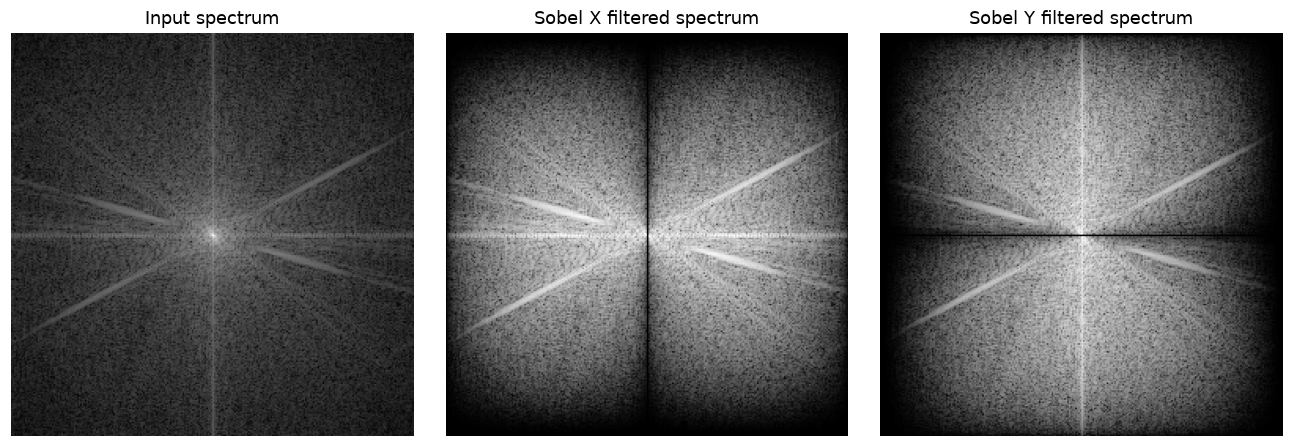

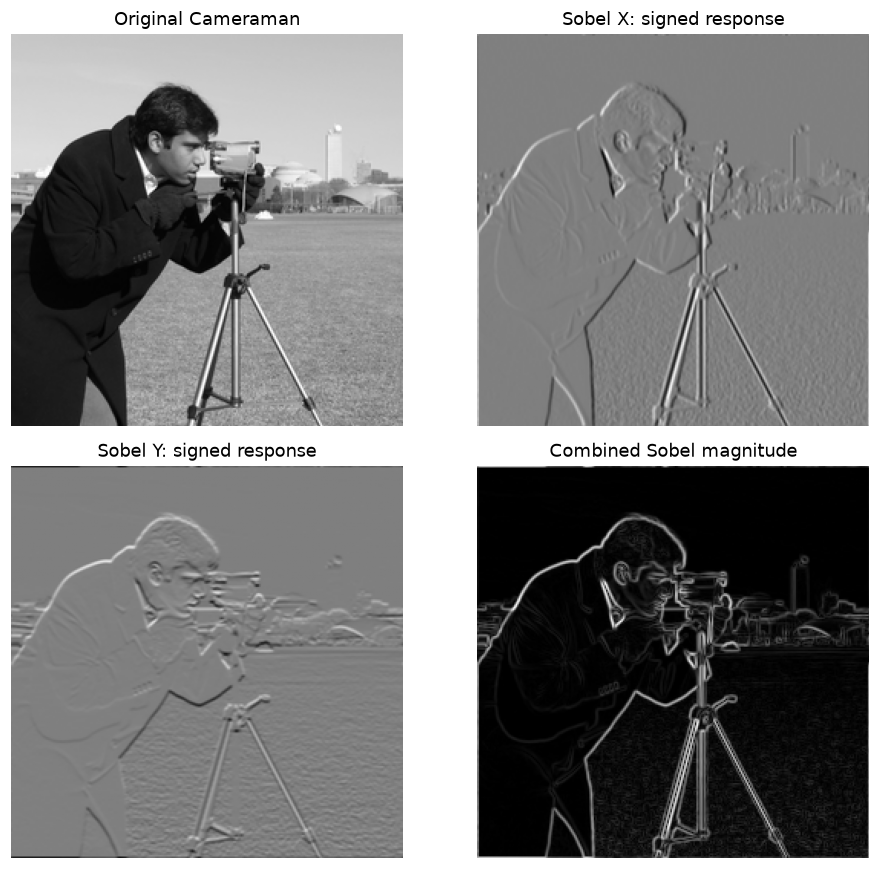

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, spectrum, title in zip(
    axes, [F, F_x, F_y],
    ['Input spectrum', 'Sobel X filtered spectrum', 'Sobel Y filtered spectrum']
):
    ax.imshow(np.log1p(np.abs(fftshift(spectrum))), cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
limit = max(np.max(np.abs(gx)), np.max(np.abs(gy)))
axes[0, 0].imshow(image, cmap='gray', vmin=0, vmax=1)
axes[0, 1].imshow(gx, cmap='gray', vmin=-limit, vmax=limit)
axes[1, 0].imshow(gy, cmap='gray', vmin=-limit, vmax=limit)
axes[1, 1].imshow(magnitude, cmap='gray', vmin=0)
for ax, title in zip(axes.flat, ['Original Cameraman',
                                'Sobel X: signed response',
                                'Sobel Y: signed response',
                                'Combined Sobel magnitude']):
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Numerical verification

Image-sized FFT filtering assumes periodic boundaries and performs circular convolution. I check my frequency-domain results against direct spatial circular convolution, using the same kernel origin and boundary rule. A comparison against zero-padded or reflected spatial filtering would differ at the borders. I also check that a constant image produces zero derivative, the inverse transforms have negligible imaginary residuals, and every result is finite.

In [5]:
def spatial_circular_convolution(array, kernel):
    result = np.zeros_like(array, dtype=float)
    cy, cx = kernel.shape[0] // 2, kernel.shape[1] // 2
    for row in range(kernel.shape[0]):
        for col in range(kernel.shape[1]):
            result += kernel[row, col] * np.roll(
                array, shift=(row-cy, col-cx), axis=(0, 1)
            )
    return result

ref_x = spatial_circular_convolution(image, sobel_x)
ref_y = spatial_circular_convolution(image, sobel_y)
for name, actual, expected in [('Sobel X', gx, ref_x),
                               ('Sobel Y', gy, ref_y)]:
    error = np.max(np.abs(actual - expected))
    print(f'{name} maximum FFT/spatial error: {error:.3e}')
    np.testing.assert_allclose(actual, expected, atol=1e-12, rtol=0)

for transfer in [H_x, H_y, laplacian_filter]:
    constant_response = ifft2(fft2(np.ones_like(image)) * transfer)
    assert np.max(np.abs(constant_response)) < 1e-12
for result in [gx_complex, gy_complex, laplacian_complex]:
    assert np.isfinite(result).all()
    assert np.max(np.abs(result.imag)) < 1e-12
assert np.isfinite(magnitude).all() and np.all(magnitude >= 0)
print(f'Magnitude range: {magnitude.min():.6f} to {magnitude.max():.6f}')
print('All numerical checks passed.')

Sobel X maximum FFT/spatial error: 2.109e-15
Sobel Y maximum FFT/spatial error: 2.567e-15
Magnitude range: 0.000000 to 3.727880
All numerical checks passed.


## 6. My observations and conclusion

I can see the cameraman, camera, tripod, and building boundaries in the filtered images. Sobel X emphasizes vertical boundaries, while Sobel Y emphasizes horizontal boundaries. The combined magnitude preserves edges from both directions. The signed Laplacian shows positive and negative changes around boundaries and emphasizes fine detail.

My FFT Sobel outputs agree with direct circular convolution to floating-point precision. Any visible image-border response is consistent with the periodic boundary assumption; it is not a kernel-centering error. For nonperiodic filtering, I would pad the image and crop the result with a clearly specified boundary rule.

Source: STUDENT PROCEDURAL MANUAL - Lab 6 - Tagged.pdf, procedural task and assessment. The input is the bundled scikit-image data.camera() image. I use ARTI403 as requested and as shown on the manual cover (the session-plan page says ARTI404).